# El XGBoost de 100 columnas con otras semillas

Este notebook es el paso 2 de la carpeta `semillas`: entrena el **XGBoost (A)** con las semillas 1, 2, 3 y 4, con el mismo código de `modelo_a_xgboost_100_features/1_entrenamiento.ipynb`.

La semilla del XGBoost controla dos cosas:
- **las máscaras de canales:** qué combinación se le sortea a cada época de entrenamiento (`default_rng([S, fold])` en los folds y `[S, 99]` en el final);
- **el submuestreo** de filas y columnas de cada árbol (`random_state`).

Las 100 columnas son las del sistema en producción (`modelo/modelo_a_xgboost_100_features/columnas.json`) y no cambian con la semilla: se eligieron una sola vez, con la ganancia del XGBoost de 719 columnas.

El desarrollo se organiza de la siguiente manera:

1. **Librerías**
2. **Rutas y parámetros**
3. **Datos**
4. **Enmascaramiento de canales**
5. **Entrenamiento**
6. **Resultados**
7. **Usar un modelo guardado**
8. **Conclusiones**

## 1. Librerías

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

Las predicciones de cada semilla van en `data/procesados/semillas/semilla_S/modelo_a_xgboost_100_features/folds/` y el modelo final en `experimentacion/semillas/modelos/semilla_S/modelo_a_xgboost_100_features/`.

Con `PRUEBA = True` se entrena 1 fold de la semilla 1 con 50 rondas, solo para comprobar que todo corre.

In [2]:
# Raíz del repositorio: la carpeta que tiene particiones.json
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())
RASGOS = RAIZ / "data" / "procesados" / "modelo_a_xgboost" / "rasgos.parquet"   # tabla de 719 rasgos
COLUMNAS = RAIZ / "modelo" / "modelo_a_xgboost_100_features" / "columnas.json"   # las 100 del sistema
FOLDS_42 = RAIZ / "data" / "procesados" / "modelo_a_xgboost_100_features" / "folds"   # la semilla 42
SALIDA = RAIZ / "data" / "procesados" / "semillas"
MODELOS = RAIZ / "experimentacion" / "semillas" / "modelos"

SEMILLAS = [1, 2, 3, 4]
PRUEBA = False
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]
if PRUEBA:
    SEMILLAS = SEMILLAS[:1]


def carpeta(semilla):
    """Predicciones de los folds y del final de una semilla."""
    return SALIDA / f"semilla_{semilla}" / "modelo_a_xgboost_100_features" / ("folds_prueba" if PRUEBA else "folds")

## 3. Datos

Los mismos 16 sujetos de test, los mismos 5 folds y las mismas 12 combinaciones.

In [3]:
# Partición por sujeto y las 12 combinaciones
particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = {k: tuple(v) for k, v in particion["combinaciones"].items()}
print(f"{len(particion['sujetos_test'])} sujetos de test, {len(particion['sujetos_desarrollo'])} de desarrollo, "
      f"{len(particion['folds'])} folds, {len(CONFIGS)} combinaciones")

16 sujetos de test, 62 de desarrollo, 5 folds, 12 combinaciones


Leemos la tabla de rasgos de `modelo_a_xgboost/1_preprocesamiento.ipynb` y la lista de las 100 columnas.

In [4]:
# Tabla de rasgos y las 100 columnas
META_COLS = ["night", "subject", "epoch_idx", "y"]
full = pd.read_parquet(RASGOS)
cols = json.loads(COLUMNAS.read_text())
assert set(cols) <= set(full.columns)
print(f"tabla: {full.shape[0]:,} épocas · el modelo usa {len(cols)} de sus {full.shape[1] - len(META_COLS)} columnas")

tabla: 195,767 épocas · el modelo usa 100 de sus 719 columnas


## 4. Enmascaramiento de canales

Las mismas funciones de `modelo_a_xgboost/2_entrenamiento.ipynb`: a cada época se le sortea una de las 12 combinaciones y las columnas de los canales ausentes se ponen en NaN.

In [5]:
# Funciones para saber qué columnas dependen de cada canal y apagar los ausentes
CHANNELS_ALL = ("fpz", "pz", "eog", "emg")
CROSS = {"corr_fpz": "fpz"}  # rasgos con prefijo de un canal que también usan otro


def channel_index(cols):
    ch = np.array([c.split("_")[0] for c in cols])
    idx = {c: set(np.where(ch == c)[0]) for c in CHANNELS_ALL}
    for i, col in enumerate(cols):
        for key, other in CROSS.items():
            if key in col:
                idx[other].add(i)
    return {c: np.array(sorted(v), dtype=int) for c, v in idx.items()}


def apply_mask(X, configs_per_row, idx):
    """Pone en NaN las columnas de los canales ausentes de cada fila. Modifica X."""
    names = np.asarray(configs_per_row)
    for cfg, chans in CONFIGS.items():
        r = np.where(names == cfg)[0]
        if len(r) == 0:
            continue
        for ch in CHANNELS_ALL:
            if ch not in chans:
                X[np.ix_(r, idx[ch])] = np.nan
    return X


def random_mask(df, cols, idx, rng):
    X = df[cols].to_numpy(np.float32, copy=True)
    return apply_mask(X, rng.choice(list(CONFIGS), size=len(X)), idx)


idx = channel_index(cols)
pd.Series({c: len(v) for c, v in idx.items()}).to_frame("columnas").T

,fpz,pz,eog,emg
columnas,51,40,5,3


## 5. Entrenamiento

### Hiperparámetros y funciones

Los mismos hiperparámetros, pesos por clase y funciones para predecir. La función de entrenamiento ahora recibe la semilla.

In [6]:
# Hiperparámetros del XGBoost y pesos por clase
PARAMS = {
    "objective": "multi:softprob", "tree_method": "hist", "eval_metric": "mlogloss", "n_jobs": -1,
    "learning_rate": 0.03394046833983564, "max_depth": 10, "min_child_weight": 43.70990468130503,
    "subsample": 0.9041986740582306, "colsample_bytree": 0.4436910153386966,
    "reg_lambda": 0.019634341572933336, "gamma": 3.4211651325607844,
}
ALPHA = 0.4401524937396013
N_MAX = 50 if PRUEBA else 2000


def class_weights(y, alpha=ALPHA):
    return compute_sample_weight("balanced", y) ** alpha

In [7]:
# Función para entrenar un XGBoost con canales enmascarados y una semilla
def rows(subjects, labeled_only=True):
    m = full.subject.isin(list(subjects))
    return full[m & (full.y >= 0)] if labeled_only else full[m]


def fit(train_subj, rng, semilla, val_subj=None, n_estimators=N_MAX):
    tr = rows(train_subj)
    p = {**PARAMS, "random_state": semilla}
    Xtr = random_mask(tr, cols, idx, rng)
    if val_subj is None:
        model = xgb.XGBClassifier(**p, n_estimators=n_estimators)
        model.fit(Xtr, tr.y, sample_weight=class_weights(tr.y), verbose=False)
        return model
    va = rows(val_subj)
    Xva = random_mask(va, cols, idx, rng)
    model = xgb.XGBClassifier(**p, n_estimators=n_estimators, early_stopping_rounds=100)
    model.fit(Xtr, tr.y, sample_weight=class_weights(tr.y), eval_set=[(Xva, va.y)],
              sample_weight_eval_set=[class_weights(va.y)], verbose=False)
    return model

In [8]:
# Funciones para predecir con las 12 combinaciones y guardar las predicciones
def predict_all_configs(model, subjects):
    """combinación -> noche -> (y, probabilidades), con todas las épocas enmascaradas igual."""
    d = rows(subjects, labeled_only=False)
    base_x = d[cols].to_numpy(np.float32)
    groups = d.groupby("night").indices
    out = {}
    for cfg in CONFIGS:
        proba = model.predict_proba(apply_mask(base_x.copy(), [cfg] * len(base_x), idx))
        out[cfg] = {n: (d.y.values[i], proba[i]) for n, i in groups.items()}
    return out


def save_preds(path, preds):
    arr = {}
    for cfg, p in preds.items():
        for n, (y, pr) in p.items():
            arr[f"{cfg}__{n}__y"], arr[f"{cfg}__{n}__pred"] = y, pr
    np.savez_compressed(path, **arr)


def load_preds(path):
    z = np.load(path)
    out = {}
    for k in z.files:
        cfg, n, kind = k.split("__")
        if kind == "y":
            out.setdefault(cfg, {})[n] = (z[k], z[f"{cfg}__{n}__pred"])
    return out

### Las 4 semillas

Para cada semilla, un modelo por fold (con early stopping sobre los sujetos de validación del fold) y el modelo final, con los 62 sujetos de desarrollo y el promedio de rondas de los folds. Si se corta, al volver a correr retoma desde lo último guardado.

In [9]:
# Función para entrenar los 5 folds y el modelo final de una semilla
folds = particion["folds"][:1] if PRUEBA else particion["folds"]


def entrenar_semilla(s):
    """Devuelve las rondas de cada fold y del final. Si se corta, retoma desde lo guardado."""
    d = carpeta(s)
    d.mkdir(parents=True, exist_ok=True)
    rondas = []
    for f in folds:
        path, meta = d / f"fold_{f['fold']}.npz", d / f"fold_{f['fold']}.json"
        if not meta.exists():
            m = fit(f["train"], np.random.default_rng([s, f["fold"]]), s, val_subj=f["val"])
            save_preds(path, predict_all_configs(m, f["test"]))
            meta.write_text(json.dumps({"rondas": m.best_iteration + 1}))
        rondas.append(json.loads(meta.read_text())["rondas"])

    n_final = int(np.mean(rondas))
    if not (d / "final.npz").exists():
        final = fit(particion["sujetos_desarrollo"], np.random.default_rng([s, 99]), s, n_estimators=n_final)
        save_preds(d / "final.npz", predict_all_configs(final, particion["sujetos_test"]))
        if not PRUEBA:
            destino = MODELOS / f"semilla_{s}" / "modelo_a_xgboost_100_features"
            destino.mkdir(parents=True, exist_ok=True)
            final.save_model(destino / "xgb.json")
            (destino / "columnas.json").write_text(json.dumps(cols))
    return rondas + [n_final]

In [ ]:
# Entrenamiento de las 4 semillas
RONDAS = {}
for s in SEMILLAS:
    RONDAS[s] = entrenar_semilla(s)
    print(f"semilla {s}: folds {RONDAS[s][:-1]} rondas · final {RONDAS[s][-1]}")

semilla 1: folds [1073, 718, 428, 413, 385] rondas · final 603
semilla 2: folds [873, 653, 770, 493, 492] rondas · final 656
semilla 3: folds [1003, 492, 828, 540, 858] rondas · final 744
semilla 4: folds [1069, 606, 420, 346, 580] rondas · final 604


## 6. Resultados

### Rondas

Cuántas rondas eligió el early stopping en cada fold, junto a las de la semilla 42 (`modelo_a_xgboost_100_features/1_entrenamiento.ipynb`).

In [11]:
# Rondas de cada fold y del final, con la semilla 42
r42 = [json.loads((FOLDS_42 / f"fold_{f['fold']}.json").read_text())["rondas"] for f in folds]
r42.append(int(np.mean(r42)))
pd.DataFrame({f"semilla {s}": r for s, r in {42: r42, **RONDAS}.items()},
             index=[f"fold {f['fold'] + 1}" for f in folds] + ["final"]).T

,fold 1,fold 2,fold 3,fold 4,fold 5,final
semilla 42,703,753,477,374,407,542
semilla 1,1073,718,428,413,385,603
semilla 2,873,653,770,493,492,656
semilla 3,1003,492,828,540,858,744
semilla 4,1069,606,420,346,580,604


### MF1 por combinación

**CV:** predicciones fuera de fold de los 62 sujetos de desarrollo. **Test:** los 16 sujetos de test. Solo se evalúan las épocas con etiqueta. Las dos últimas columnas son la media y la desviación estándar de las 5 semillas.

In [12]:
# Funciones para calcular las métricas
def compute_metrics(y_true, y_pred):
    f1 = f1_score(y_true, y_pred, labels=range(5), average=None, zero_division=0)
    return {"acc": accuracy_score(y_true, y_pred), "mf1": f1.mean(), "kappa": cohen_kappa_score(y_true, y_pred),
            **{f"f1_{s}": v for s, v in zip(ESTADIOS, f1)},
            "confusion": confusion_matrix(y_true, y_pred, labels=range(5))}


def metrics_of(preds):
    y = np.concatenate([y for y, _ in preds.values()])
    p = np.concatenate([p.argmax(1) for _, p in preds.values()])
    return compute_metrics(y[y >= 0], p[y >= 0])

In [13]:
# MF1 del XGBoost por combinación y semilla: CV y test
def cv_y_test(carpeta_preds):
    oof = {c: {} for c in CONFIGS}
    for f in folds:
        for c, p in load_preds(carpeta_preds / f"fold_{f['fold']}.npz").items():
            oof[c].update(p)
    return oof, load_preds(carpeta_preds / "final.npz")


def con_media(tabla):
    """Agrega la media y la desviación estándar entre semillas."""
    return tabla.assign(media=tabla.mean(1), de=tabla.std(1))


cv, test = {}, {}
for s in [42, *SEMILLAS]:
    oof, te = cv_y_test(FOLDS_42 if s == 42 else carpeta(s))
    cv[f"semilla {s}"] = {c: metrics_of(oof[c])["mf1"] for c in CONFIGS}
    test[f"semilla {s}"] = {c: metrics_of(te[c])["mf1"] for c in CONFIGS}
cv_a, test_a = con_media(pd.DataFrame(cv)), con_media(pd.DataFrame(test))
print("CV (62 sujetos de desarrollo)")
display(cv_a.style.format(precision=3))
print("test (16 sujetos)")
test_a.style.format(precision=3)

CV (62 sujetos de desarrollo)


,semilla 42,semilla 1,semilla 2,semilla 3,semilla 4,media,de
fpz,0.760,0.761,0.760,0.760,0.760,0.760,0.000
pz,0.716,0.717,0.717,0.716,0.718,0.717,0.001
eeg2,0.776,0.776,0.776,0.778,0.777,0.777,0.001
fpz_eog,0.770,0.771,0.771,0.771,0.771,0.771,0.001
pz_eog,0.742,0.741,0.741,0.742,0.741,0.742,0.000
eeg2_eog,0.783,0.783,0.784,0.785,0.783,0.784,0.001
fpz_emg,0.769,0.769,0.769,0.768,0.770,0.769,0.001
pz_emg,0.728,0.728,0.729,0.727,0.729,0.728,0.001
eeg2_emg,0.781,0.782,0.782,0.782,0.783,0.782,0.001
fpz_eog_emg,0.778,0.778,0.778,0.778,0.779,0.778,0.000


test (16 sujetos)


,semilla 42,semilla 1,semilla 2,semilla 3,semilla 4,media,de
fpz,0.718,0.721,0.720,0.722,0.722,0.721,0.002
pz,0.690,0.692,0.692,0.689,0.691,0.691,0.001
eeg2,0.736,0.733,0.736,0.734,0.737,0.735,0.001
fpz_eog,0.735,0.737,0.735,0.734,0.737,0.736,0.001
pz_eog,0.705,0.709,0.708,0.708,0.708,0.708,0.002
eeg2_eog,0.745,0.744,0.746,0.746,0.747,0.746,0.001
fpz_emg,0.731,0.731,0.731,0.731,0.733,0.731,0.001
pz_emg,0.706,0.706,0.707,0.706,0.703,0.706,0.001
eeg2_emg,0.746,0.744,0.747,0.746,0.746,0.746,0.001
fpz_eog_emg,0.744,0.744,0.742,0.743,0.743,0.743,0.001


La misma tabla del test en una gráfica: si las marcas de una combinación están juntas, la semilla casi no cambia el resultado.

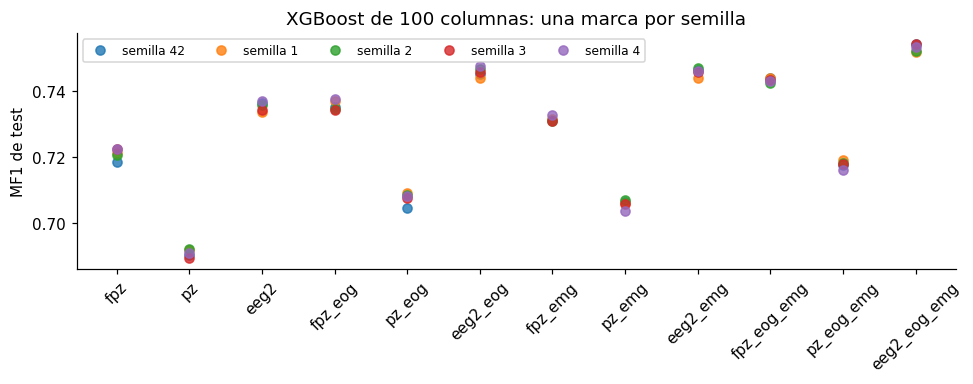

In [14]:
# MF1 de test de cada semilla por combinación
ax = test_a.drop(columns=["media", "de"]).plot(style="o", figsize=(9, 3.6), rot=45, alpha=0.8)
ax.set_xticks(range(len(CONFIGS)), CONFIGS)
ax.set_ylabel("MF1 de test")
ax.set_title("XGBoost de 100 columnas: una marca por semilla")
ax.legend(fontsize=8, ncol=5)
plt.tight_layout()
plt.show()

## 7. Usar un modelo guardado

Se carga el `xgb.json` de la semilla 1, se le pasan los rasgos de una noche de test con los canales ausentes en NaN, y se comprueba que da lo mismo que las predicciones guardadas.

In [15]:
# Cargar el modelo guardado de la semilla 1 y predecir una noche de test con Fpz-Cz
s = SEMILLAS[0]
modelo = xgb.Booster()
modelo.load_model(MODELOS / f"semilla_{s}" / "modelo_a_xgboost_100_features" / "xgb.json")
columnas = json.loads((MODELOS / f"semilla_{s}" / "modelo_a_xgboost_100_features" / "columnas.json").read_text())
assert columnas == cols

test_s = load_preds(carpeta(s) / "final.npz")
noche = sorted(test_s["fpz"])[0]
d = full[full.night == noche]
X = apply_mask(d[columnas].to_numpy(np.float32), ["fpz"] * len(d), channel_index(columnas))
proba = modelo.predict(xgb.DMatrix(X))
assert np.allclose(proba, test_s["fpz"][noche][1], atol=1e-6)

y, pred = d.y.values, proba.argmax(1)
m = compute_metrics(y[y >= 0], pred[y >= 0])
print(f"semilla {s} · {noche}, solo Fpz-Cz: {len(d)} épocas · MF1 {m['mf1']:.3f} · κ {m['kappa']:.3f}")

semilla 1 · SC4001, solo Fpz-Cz: 841 épocas · MF1 0.802 · κ 0.842


## 8. Conclusiones

- Con las 4 semillas nuevas, el early stopping elige cantidades de rondas muy distintas (el modelo final va de 542 a 744), porque la semilla cambia qué combinación de canales le toca a cada época.
- Aun así, el XGBoost casi no depende de la semilla: en las 12 combinaciones, el MF1 varía con una desviación estándar de 0.001 o menos en la CV y de 0.002 o menos en el test.
- La semilla 42 no se aparta de las otras: como mucho, queda a 0.003 de la media.
- El XGBoost es la pieza más estable del sistema; la red varía un poco más (ver `1_entrenamiento_red.ipynb`).